<a href="https://colab.research.google.com/github/Rizm10/brownfield-development-friction-/blob/main/brownfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brownfield Development Friction

England's brownfield registers identify previously developed land with potential for future development. However, identifying a site as brownfield land does not necessarily mean that development would be straightforward.

This project investigates how frequently brownfield sites overlap with major planning and environmental constraints, and whether publicly available planning data can be used to identify sites that appear comparatively less constrained.

The analysis uses data from the UK Government Planning Data platform and combines brownfield land records with spatial planning constraint datasets.

### Research Question

**Which brownfield development opportunities appear least constrained by the planning designations available in the national Planning Data platform?**

## 2. Retrieve Brownfield Sites

The first stage is to retrieve brownfield land records for a single London borough.

Brent is used as the initial study area. Starting with one borough keeps the spatial analysis manageable while allowing the full constraint-analysis pipeline to be tested before considering expansion to a wider area.

The Planning Data API allows brownfield land records to be filtered spatially using the boundary of a local planning authority.

In [ ]:
import requests
import pandas as pd
import geopandas as gpd

In [ ]:
# Planning Data api
base_url = "https://www.planning.data.gov.uk/entity.json"
params = { "dataset": "local-planning-authority",
          "limit" : 500,
          "field": ["name", "entity"]
}

response = requests.get(base_url,params = params)
response.raise_for_status()

lpa_data = response.json()

# Inspect response structure
lpa_data.keys()



dict_keys(['entities', 'links', 'count'])

In [ ]:
lpas = pd.DataFrame(lpa_data["entities"])

#Find Brent
brent_lpa = lpas[
    lpas["name"].str.contains("Brent", case=False, na=False)
]

brent_lpa


,entity,name
155,626156,Brentwood LPA
204,626205,Brent LPA


In [ ]:
params = {
    "dataset": "brownfield-land",
    "geometry_entity": 626205,
    "geometry_relation": "within",
    "limit": 100
}

response = requests.get(base_url, params=params)

print("Status:", response.status_code)
print("URL:", response.url)
print("Response:")
print(response.text)

Status: 200
URL: https://www.planning.data.gov.uk/entity.json?dataset=brownfield-land&geometry_entity=626205&geometry_relation=within&limit=100
Response:
{"entities":[{"entry-date":"2019-12-13","start-date":"2017-12-15","end-date":"2021-09-04","entity":1717145,"name":"BR00027","dataset":"brownfield-land","typology":"geography","reference":"BR00027","prefix":"brownfield-land","organisation-entity":42,"geometry":"","point":"POINT (-0.284618 51.559955)","quality":"authoritative","notes":"16/3408. Expired.","hectares":"1.4","deliverable":"yes","site-address":"Raglan Court & Garages, Raglan Court, Empire Way, Wembley, HA9","site-plan-url":"https://maps.london.gov.uk/brownfield-site-register","ownership-status":"not-owned-by-a-public-authority","maximum-net-dwellings":"72","minimum-net-dwellings":"72","planning-permission-date":"2018-09-04","planning-permission-type":"full-planning-permission","planning-permission-status":"permissioned","planning-permission-history":"https://pa.brent.gov.uk/

In [ ]:
all_brownfield = []

offset = 0
limit = 100

while True:
    params = {
        "dataset": "brownfield-land",
        "geometry_entity": brent_entity,
        "geometry_relation": "within",
        "limit": limit,
        "offset": offset
    }

    response = requests.get(base_url, params=params)
    response.raise_for_status()

    page = response.json()
    all_brownfield.extend(page["entities"])

    print(f"Fetched {len(page['entities'])} records at offset {offset}")

    if len(page["entities"]) < limit:
        break

    offset += limit

brownfield_df = pd.DataFrame(all_brownfield)

print("Total records fetched:", len(brownfield_df))
print("Unique entities:", brownfield_df["entity"].nunique())

Fetched 100 records at offset 0
Fetched 100 records at offset 100
Fetched 87 records at offset 200
Total records fetched: 287
Unique entities: 287


In [ ]:
# Preserve full historical extract
brownfield_history = brownfield_df.copy()

# Current register entries: no end date
current_brownfield = brownfield_df[
    brownfield_df['end-date'].fillna("").eq("")].copy()

print("Historical records:", len(brownfield_history))
print("Current active records:", len(current_brownfield))

current_brownfield[
    [
        "entity",
        "reference",
        "site-address",
        "hectares",
        "planning-permission-status",
        "ownership-status",
        "minimum-net-dwellings",
        "maximum-net-dwellings",
        "entry-date",
        "start-date",
        "end-date"
    ]
].head(10)


Historical records: 287
Current active records: 213


,entity,reference,site-address,hectares,planning-permission-status,ownership-status,minimum-net-dwellings,maximum-net-dwellings,entry-date,start-date,end-date
1,1717146,BR00045,"Stadium Retail Park, HA9",1.67,permissioned,not-owned-by-a-public-authority,966,966,2026-04-10,2017-12-15,
5,1717150,BR00008,"Olympic Office Centre, 8 Fulton Road",0.49,permissioned,not-owned-by-a-public-authority,253,253,2026-04-10,2017-12-15,
6,1717151,BR00003,Wembley High Road,2.25,permissioned,not-owned-by-a-public-authority,394,394,2026-04-10,2017-12-15,
7,1717152,BR00004,"Heron House, 109-115 Wembley Hill Road, Wemble...",0.15,permissioned,not-owned-by-a-public-authority,40,40,2019-12-13,2017-12-15,
9,1717154,BR00056,"Chancel House, Neasden Lane, NW10",1.95,not-permissioned,owned-by-a-public-authority,135,135,2019-12-13,2017-12-15,
11,1717156,BR00052,"Sunleigh Road, Off Mount Pleasant, Alperton, HA0",1.85,permissioned,not-owned-by-a-public-authority,372,372,2026-04-10,2017-12-15,
14,1717159,BR00054,"Beresford Avenue, Alperton",0.34,not-permissioned,not-owned-by-a-public-authority,30,30,2026-04-10,2017-12-15,
15,1717160,BR00050,"Euro Car Parts, Corner of Fulton Road and Fift...",1.13,pending-decision,not-owned-by-a-public-authority,450,450,2026-04-10,2017-12-15,
16,1717161,BR00049,Watkin Road,0.08,permissioned,not-owned-by-a-public-authority,662,662,2026-04-10,2017-12-15,
17,1717162,BR00048,"The Torch/Kwik Fit Euro, 1-5 Bridge Road, HA9",0.38,not-permissioned,not-owned-by-a-public-authority,485,485,2026-04-10,2017-12-15,


In [ ]:
from shapely import wkt

# Keep only active records with a usable point
current_brownfield = current_brownfield[
    current_brownfield["point"].notna() &
    current_brownfield["point"].ne("")].copy()

# Convert WKT point strings into geometry
current_brownfield["geometry"] = current_brownfield["point"].apply(wkt.loads)

brownfield_gdf = gpd.GeoDataFrame(
    current_brownfield,
    geometry="geometry",
    crs="EPSG:4326"
)

print("Active sites with usable coordinates:", len(brownfield_gdf))
print("CRS:", brownfield_gdf.crs)

brownfield_gdf[
    ["reference", "site-address", "hectares", "planning-permission-status", "geometry"]
].head()


Active sites with usable coordinates: 213
CRS: EPSG:4326


,reference,site-address,hectares,planning-permission-status,geometry
1,BR00045,"Stadium Retail Park, HA9",1.67,permissioned,POINT (-0.28104 51.56131)
5,BR00008,"Olympic Office Centre, 8 Fulton Road",0.49,permissioned,POINT (-0.27905 51.56037)
6,BR00003,Wembley High Road,2.25,permissioned,POINT (-0.28912 51.55401)
7,BR00004,"Heron House, 109-115 Wembley Hill Road, Wemble...",0.15,permissioned,POINT (-0.28756 51.55726)
9,BR00056,"Chancel House, Neasden Lane, NW10",1.95,not-permissioned,POINT (-0.24669 51.55039)


In [ ]:
# Pick the first Brent brownfield site
test_site = brownfield_gdf.iloc[0]

lat = test_site.geometry.y
lon = test_site.geometry.x

constraint_datasets  = [
   "conservation-area",
   "listed-building",
   "article-4-direction-area",
    "flood-risk-zone",
    "green-belt",
    "tree-preservation-zone"
]

params = [
    ("latitude", lat),
    ("longitude", lon),
    ("limit", 100)
]

for dataset in constraint_datasets:
    params.append(("dataset", dataset))

response = requests.get(base_url, params=params)
response.raise_for_status()

test_constraints = response.json()

print("Site:", test_site["reference"])
print("Address:", test_site["site-address"])
print("Constraints found:", test_constraints["count"])

for item in test_constraints["entities"]:
    print(item["dataset"], "->", item.get("name"))

Site: BR00045
Address: Stadium Retail Park, HA9
Constraints found: 1
flood-risk-zone -> 


## 4. Screen Brownfield Sites Against Planning Constraints

Each active brownfield site is screened against a small set of planning and environmental constraint datasets available through the Planning Data API.

The analysis checks whether the representative point for each site falls within any of the following datasets:

- Conservation areas
- Listed buildings
- Article 4 direction areas
- Flood risk zones
- Green belt
- Tree preservation zones

For each site, a binary indicator is recorded for every constraint dataset and these are combined into a simple `constraint_count`.

A higher count indicates that the site appears to be affected by more of the selected constraints.

### Important limitation

The brownfield records used here contain representative point coordinates rather than full site polygons. As a result, this is a point-based screening exercise rather than a complete polygon-overlap analysis.

A site may therefore overlap a constraint even if its representative point does not fall inside that constraint area. Likewise, a missing match should not be interpreted as proof that no planning constraint exists, particularly where source coverage is incomplete.

The purpose of this stage is to create a transparent first-pass development-friction screen, not a definitive planning assessment.

In [ ]:
from time import sleep

# Add empty boolean columns for each constraint
for dataset in constraint_datasets:
    brownfield_gdf[dataset] = False

brownfield_gdf["constraint_count"] = 0

for idx, row in brownfield_gdf.iterrows():
    lat = row.geometry.y
    lon = row.geometry.x

    params = [
        ("latitude", lat),
        ("longitude", lon),
        ("limit", 100)
    ]

    for dataset in constraint_datasets:
        params.append(("dataset", dataset))

    response = requests.get(base_url, params=params)
    response.raise_for_status()

    result = response.json()
    found = {item["dataset"] for item in result["entities"]}

    for dataset in constraint_datasets:
        brownfield_gdf.at[idx, dataset] = dataset in found

    brownfield_gdf.at[idx, "constraint_count"] = len(found)

    if (idx + 1) % 25 == 0:
        print(f"Processed {idx + 1} sites")

    sleep(0.05)

print("Done")

Processed 75 sites
Processed 125 sites
Processed 150 sites
Processed 175 sites
Processed 200 sites
Processed 225 sites
Processed 250 sites
Processed 275 sites
Done


In [ ]:
brownfield_gdf["constraint_count"].value_counts().sort_index()

,count
constraint_count,
0,51
1,134
2,27
3,1


In [ ]:
constraint_summary = (
    brownfield_gdf[constraint_datasets]
    .sum()
    .sort_values(ascending = False)
    .to_frame(name = "sites")
)

constraint_summary["percent_of_sites"] = (
    constraint_summary["sites"] / len(brownfield_gdf) * 100).round(1)

constraint_summary


,sites,percent_of_sites
article-4-direction-area,159,74.6
conservation-area,20,9.4
flood-risk-zone,11,5.2
tree-preservation-zone,1,0.5
listed-building,0,0.0
green-belt,0,0.0


In [ ]:
non_article4 = [
    "conservation-area",
    "flood-risk-zone",
    "tree-preservation-zone",
    "listed-building",
    "green-belt"
]

brownfield_gdf["non_article4_constraint_count"] = (
    brownfield_gdf[non_article4].sum(axis=1)
)

summary_non_article4 = (
    brownfield_gdf["non_article4_constraint_count"]
    .value_counts()
    .sort_index()
    .to_frame(name="sites")
)

summary_non_article4["percent_of_sites"] = (
    summary_non_article4["sites"] / len(brownfield_gdf) * 100
).round(1)

summary_non_article4

,sites,percent_of_sites
non_article4_constraint_count,,
0,182,85.4
1,30,14.1
2,1,0.5


In [ ]:
non_article4_sites = brownfield_gdf[
    brownfield_gdf["non_article4_constraint_count"] > 0
].copy()

cols = [
    "reference",
    "site-address",
    "hectares",
    "planning-permission-status",
    "non_article4_constraint_count",
    "conservation-area",
    "flood-risk-zone",
    "tree-preservation-zone",
    "listed-building",
    "green-belt"
]

non_article4_sites[
    cols
].sort_values(
    ["non_article4_constraint_count", "hectares"],
    ascending=[False, False]
).head(20)

,reference,site-address,hectares,planning-permission-status,non_article4_constraint_count,conservation-area,flood-risk-zone,tree-preservation-zone,listed-building,green-belt
270,BR00275,"Chalfont House Garages, Verney Street, London,...",NaN,NaN,2,True,True,False,False,False
53,BR00064,Bridge Park & Unisys Building,2.72,not-permissioned,1,False,True,False,False,False
1,BR00045,"Stadium Retail Park, HA9",1.67,permissioned,1,False,True,False,False,False
169,BR00179,Brook Avenue,1.5,not-permissioned,1,False,True,False,False,False
117,BR00122,Coombe Road,1.36,permissioned,1,False,True,False,False,False
162,BR00169,"Argenta House, Argenta Way, London, NW10 0AZ",1.22,permissioned,1,False,True,False,False,False
262,BR00049.0,Watkin Road,0.99,NaN,1,False,True,False,False,False
229,BR00248,Former Wembley Youth Centre / Dennis Jackson C...,0.96,not-permissioned,1,False,False,True,False,False
173,BR00183,College of North West London Wembley,0.37,not-permissioned,1,False,True,False,False,False
114,BR00119,"Prospect House, North Circular Road",0.24,permissioned,1,False,True,False,False,False


## 5. Data Quality Check: Unique Brownfield Sites

Before constructing a development-friction ranking, the active brownfield records are checked for duplicate or inconsistent site references.

The Planning Data platform stores records as entities, but multiple entities may refer to the same underlying brownfield site. Reference values may also vary slightly in formatting.

The analysis therefore checks:

- number of active entities
- number of unique site references
- duplicated references
- missing site area
- missing planning-permission status

This prevents duplicated or incomplete records from being treated as separate development opportunities.

In [ ]:
# Normalise brownfield site references
brownfield_gdf["reference_clean"] = (
    brownfield_gdf["reference"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

print("Active entities:", len(brownfield_gdf))
print("Unique cleaned references:", brownfield_gdf["reference_clean"].nunique())

print("\nDuplicated cleaned references:")
print(
    brownfield_gdf[
        brownfield_gdf["reference_clean"].duplicated(keep=False)
    ][
        [
            "entity",
            "reference",
            "reference_clean",
            "site-address",
            "entry-date",
            "hectares",
            "planning-permission-status"
        ]
    ]
    .sort_values("reference_clean")
)

print("\nMissing hectares:", brownfield_gdf["hectares"].isna().sum())
print(
    "Missing planning status:",
    brownfield_gdf["planning-permission-status"].isna().sum()
)

Active entities: 213
Unique cleaned references: 208

Duplicated cleaned references:
      entity  reference reference_clean  \
17   1717162    BR00048         BR00048   
261  1741881  BR00048.0         BR00048   
16   1717161    BR00049         BR00049   
262  1741882  BR00049.0         BR00049   
14   1717159    BR00054         BR00054   
263  1741883  BR00054.0         BR00054   
112  1721511    BR00117         BR00117   
264  1741884  BR00117.0         BR00117   
169  1729384    BR00179         BR00179   
265  1741885  BR00179.0         BR00179   

                                      site-address  entry-date hectares  \
17   The Torch/Kwik Fit Euro, 1-5 Bridge Road, HA9  2026-04-10     0.38   
261                                           Asda  2026-03-10     3.08   
16                                     Watkin Road  2026-04-10     0.08   
262                                    Watkin Road  2026-03-10     0.99   
14                      Beresford Avenue, Alperton  2026-04-10     

In [ ]:
# Convert entry-date to datetime
brownfield_gdf["entry-date"] = pd.to_datetime(
    brownfield_gdf["entry-date"],
    errors="coerce"
)

# Keep the most recent active record for each cleaned site reference
brownfield_clean = (
    brownfield_gdf
    .sort_values("entry-date")
    .drop_duplicates(
        subset="reference_clean",
        keep="last"
    )
    .copy()
)

print("Rows after deduplication:", len(brownfield_clean))
print("Unique cleaned references:", brownfield_clean["reference_clean"].nunique())

print("\nRemaining missing hectares:", brownfield_clean["hectares"].isna().sum())
print(
    "Remaining missing planning status:",
    brownfield_clean["planning-permission-status"].isna().sum()
)

Rows after deduplication: 208
Unique cleaned references: 208

Remaining missing hectares: 6
Remaining missing planning status: 21


In [ ]:
constraint_summary_clean = (
    brownfield_clean[constraint_datasets]
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="sites")
)

constraint_summary_clean["percent_of_sites"] = (
    constraint_summary_clean["sites"] / len(brownfield_clean) * 100
).round(1)

print("Constraint breakdown:")
display(constraint_summary_clean)

# Any selected constraint
brownfield_clean["constraint_count"] = (
    brownfield_clean[constraint_datasets].sum(axis=1)
)

any_constraint = (brownfield_clean["constraint_count"] > 0).sum()

print(
    "\nSites with at least one selected constraint:",
    any_constraint,
    f"({any_constraint / len(brownfield_clean) * 100:.1f}%)"
)

# Non-Article-4 constraints
brownfield_clean["non_article4_constraint_count"] = (
    brownfield_clean[non_article4].sum(axis=1)
)

non_a4 = (brownfield_clean["non_article4_constraint_count"] > 0).sum()

print(
    "Sites with at least one non-Article-4 constraint:",
    non_a4,
    f"({non_a4 / len(brownfield_clean) * 100:.1f}%)"
)

Constraint breakdown:


,sites,percent_of_sites
article-4-direction-area,157,75.5
conservation-area,20,9.6
flood-risk-zone,10,4.8
tree-preservation-zone,1,0.5
listed-building,0,0.0
green-belt,0,0.0



Sites with at least one selected constraint: 160 (76.9%)
Sites with at least one non-Article-4 constraint: 30 (14.4%)


## 6. Construct a Development Friction Tier

The constraint screen shows that Article 4 direction areas are much more common than the other selected datasets.

Because of this imbalance, simply counting all constraints equally would cause the ranking to be dominated by Article 4 coverage.

Instead, sites are grouped into transparent screening tiers:

- **Tier 0 — Lower apparent friction:** no selected constraint detected
- **Tier 1 — Article 4 only:** Article 4 direction area detected, but no other selected constraint
- **Tier 2 — Additional constraint:** one non-Article-4 constraint detected, with or without Article 4
- **Tier 3 — Multiple additional constraints:** two or more non-Article-4 constraints detected

These tiers are intended as a comparative screening tool rather than a measure of planning difficulty or development viability.

In [ ]:
def assign_friction_tier(row):
    non_a4 = row["non_article4_constraint_count"]
    article4 = row["article-4-direction-area"]

    if non_a4 >= 2:
        return 3
    elif non_a4 == 1:
        return 2
    elif article4:
        return 1
    else:
        return 0


brownfield_clean["friction_tier"] = brownfield_clean.apply(
    assign_friction_tier,
    axis=1
)

tier_summary = (
    brownfield_clean["friction_tier"]
    .value_counts()
    .sort_index()
    .to_frame(name="sites")
)

tier_summary["percent_of_sites"] = (
    tier_summary["sites"] / len(brownfield_clean) * 100
).round(1)

tier_summary

,sites,percent_of_sites
friction_tier,,
0,48,23.1
1,130,62.5
2,29,13.9
3,1,0.5


## 7. Visualise Brownfield Development Friction

The cleaned brownfield sites are mapped by friction tier to show how the selected planning constraints are distributed spatially across Brent.

The map uses each site's representative point rather than its full site boundary, so it should be interpreted as a screening visual rather than a precise development-constraint map.

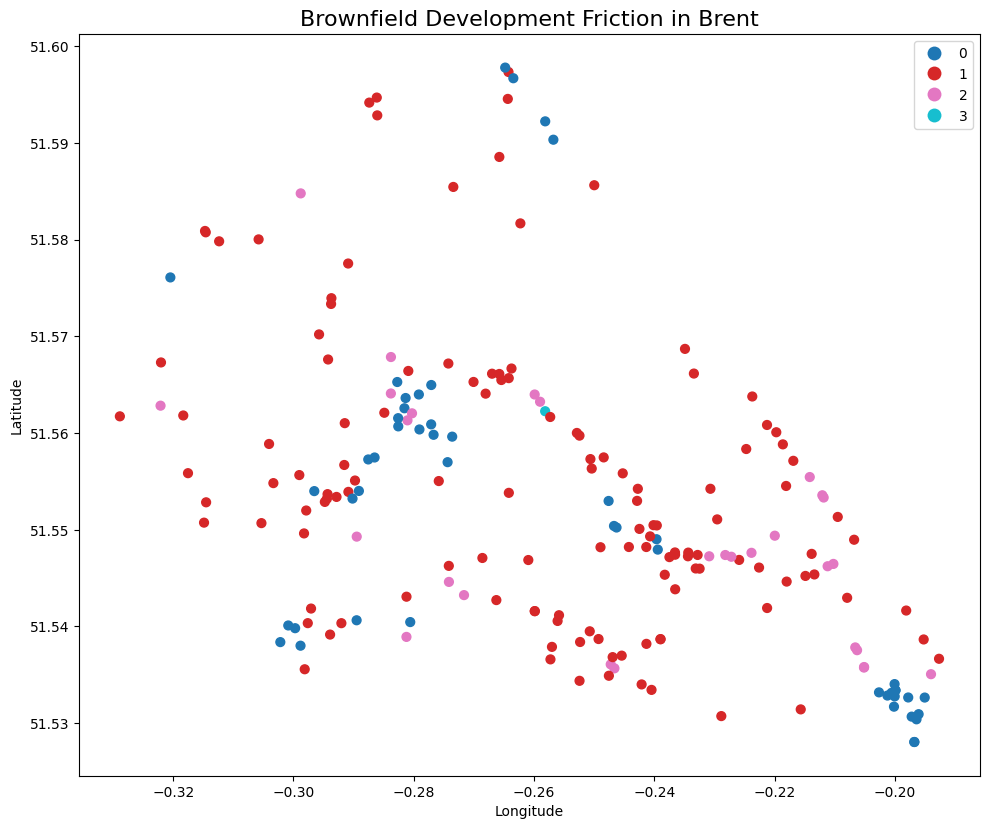

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

brownfield_clean.plot(
    ax=ax,
    column="friction_tier",
    categorical=True,
    legend=True,
    markersize=40
)

ax.set_title(
    "Brownfield Development Friction in Brent",
    fontsize=16
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [ ]:
!pip install contextily -q

## 8. Interactive Brownfield Screening Map

An interactive map is created to make the screening results easier to inspect at site level.

Each brownfield site is shown as a clickable marker containing:

- site reference
- address
- friction tier
- site area
- planning-permission status
- selected planning constraints detected at the representative point

This provides a lightweight decision-support view of the brownfield register rather than a static chart alone.

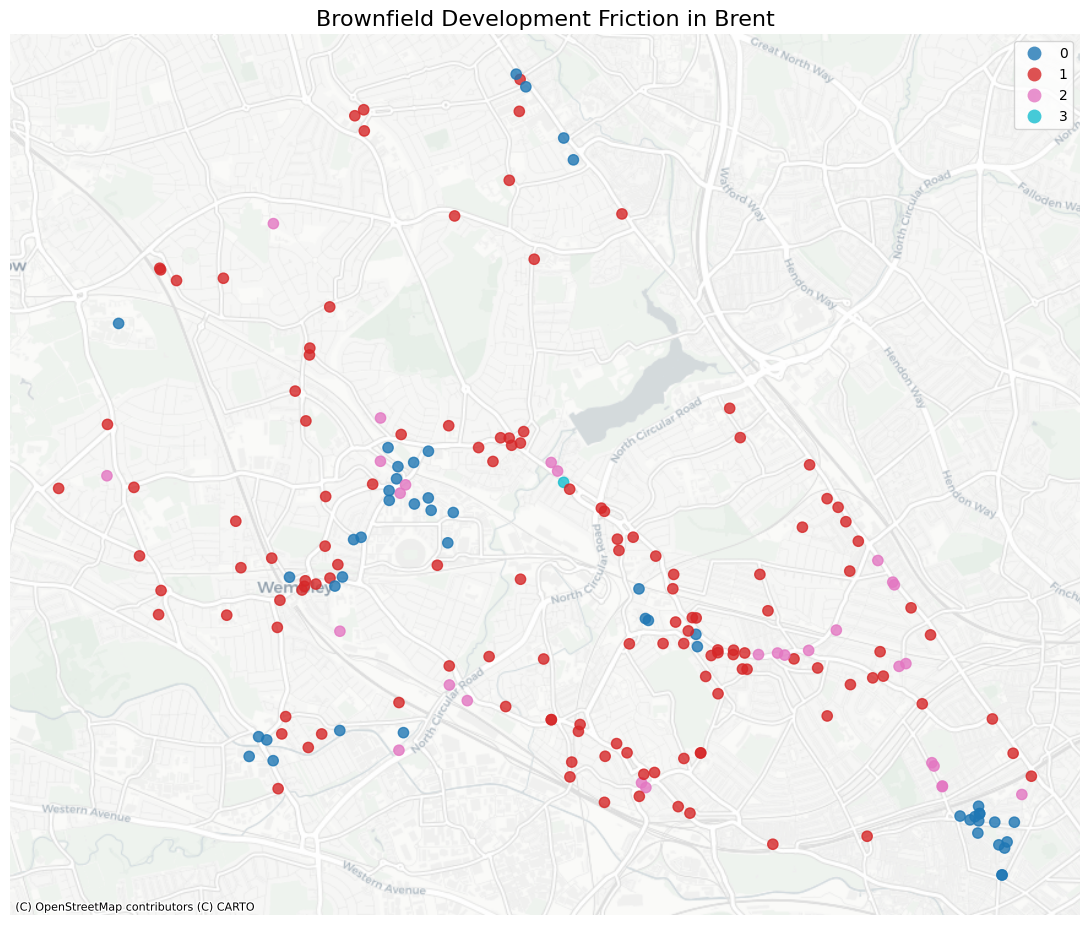

In [ ]:
import contextily as ctx

# Reproject to Web Mercator for basemap tiles
brownfield_map = brownfield_clean.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(11, 11))

brownfield_map.plot(
    ax=ax,
    column="friction_tier",
    categorical=True,
    legend=True,
    markersize=55,
    alpha=0.8
)

ctx.add_basemap(
    ax,
    source=ctx.providers.CartoDB.Positron
)

ax.set_title(
    "Brownfield Development Friction in Brent",
    fontsize=16
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
import folium

# Centre map on Brent sites
centre_lat = brownfield_clean.geometry.y.mean()
centre_lon = brownfield_clean.geometry.x.mean()

m = folium.Map(
    location=[centre_lat, centre_lon],
    zoom_start=12,
    tiles="CartoDB positron"
)

tier_colors = {
    0: "green",
    1: "blue",
    2: "orange",
    3: "red"
}

for _, row in brownfield_clean.iterrows():

    active_constraints = [
        dataset
        for dataset in constraint_datasets
        if row[dataset]
    ]

    constraints_text = (
        ", ".join(active_constraints)
        if active_constraints
        else "None detected"
    )

    hectares = (
        row["hectares"]
        if pd.notna(row["hectares"])
        else "Not available"
    )

    planning_status = (
        row["planning-permission-status"]
        if pd.notna(row["planning-permission-status"])
        else "Not available"
    )

    popup_html = f"""
    <b>{row['reference_clean']}</b><br>
    {row['site-address']}<br><br>

    <b>Friction tier:</b> {row['friction_tier']}<br>
    <b>Area:</b> {hectares} hectares<br>
    <b>Planning status:</b> {planning_status}<br>
    <b>Constraints:</b> {constraints_text}
    """

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=6,
        color=tier_colors[row["friction_tier"]],
        fill=True,
        fill_opacity=0.8,
        popup=folium.Popup(
            popup_html,
            max_width=350
        )
    ).add_to(m)

m

## 9. Rank Lower-Friction Development Opportunities

The friction tiers identify sites that appear comparatively less constrained by the selected datasets.

To make the screening more decision-relevant, lower-friction sites are ranked by their stated residential development capacity.

This step focuses primarily on:

- Tier 0 sites, where none of the selected constraints were detected
- Tier 1 sites, where only an Article 4 direction area was detected

Sites are then compared using their maximum net dwelling capacity and site area where available.

This does not represent commercial viability or planning approval likelihood. It is a simple prioritisation screen based on publicly available brownfield and planning data.

In [ ]:
# Convert capacity and area fields to numeric
for col in [
    "maximum-net-dwellings",
    "minimum-net-dwellings",
    "hectares"
]:
    brownfield_clean[col] = pd.to_numeric(
        brownfield_clean[col],
        errors="coerce"
    )

# Focus on lower-friction sites
lower_friction = brownfield_clean[
    brownfield_clean["friction_tier"].isin([0, 1])
].copy()

# Rank by maximum stated dwelling capacity
ranked_sites = lower_friction[
    [
        "reference_clean",
        "site-address",
        "friction_tier",
        "hectares",
        "minimum-net-dwellings",
        "maximum-net-dwellings",
        "planning-permission-status",
        "ownership-status"
    ]
].sort_values(
    "maximum-net-dwellings",
    ascending=False
)

ranked_sites.head(15)

,reference_clean,site-address,friction_tier,hectares,minimum-net-dwellings,maximum-net-dwellings,planning-permission-status,ownership-status
87,BR00099,"Northfield Industrial Estate, Beresford Avenue...",0,6.01,2426.0,2426.0,permissioned,not-owned-by-a-public-authority
180,BR00190,BEGA2 - Staples Corner Growth Area,1,42.67,1989.0,1989.0,not-permissioned,not-owned-by-a-public-authority
171,BR00181,Wembley Retail Park,0,3.89,1978.0,1978.0,permissioned,not-owned-by-a-public-authority
179,BR00189,Neasden Stations Growth Area,0,13.01,1879.0,1879.0,not-permissioned,mixed-ownership
187,BR00198,Northwick Park Growth Area,0,30.53,1585.0,1585.0,not-permissioned,mixed-ownership
172,BR00182,First Way,0,3.92,1043.0,1043.0,not-permissioned,not-owned-by-a-public-authority
230,BR00249,Alperton Industrial Sites,0,3.40,829.0,829.0,permissioned,not-owned-by-a-public-authority
42,BR00053,"Woodside Avenue, Off Mount Pleasant, Alperton,...",1,2.63,698.0,698.0,permissioned,not-owned-by-a-public-authority
16,BR00049,Watkin Road,0,0.08,662.0,662.0,permissioned,not-owned-by-a-public-authority
174,BR00184,Land to South of South Way,1,1.65,500.0,500.0,not-permissioned,not-owned-by-a-public-authority


## 10. Quality Check: Capacity Relative to Site Area

Ranking sites only by stated dwelling capacity can be misleading where site-area fields are missing, inconsistent, or refer to different extents.

To identify potentially problematic records, an implied dwelling-density measure is calculated as:

**maximum net dwellings / hectares**

Extremely high values are treated as data-quality flags rather than evidence of unusually efficient development.

This step helps prevent anomalous source records from dominating the opportunity ranking.

In [ ]:
# Implied maximum dwelling density
brownfield_clean["dwellings_per_hectare"] = (
    brownfield_clean["maximum-net-dwellings"] /
    brownfield_clean["hectares"]
)

density_qa = brownfield_clean[
    [
        "reference_clean",
        "site-address",
        "friction_tier",
        "hectares",
        "maximum-net-dwellings",
        "dwellings_per_hectare",
        "planning-permission-status"
    ]
].sort_values(
    "dwellings_per_hectare",
    ascending=False
)

density_qa.head(20)

,reference_clean,site-address,friction_tier,hectares,maximum-net-dwellings,dwellings_per_hectare,planning-permission-status
16,BR00049,Watkin Road,0,0.08,662.0,8275.000000,permissioned
17,BR00048,"The Torch/Kwik Fit Euro, 1-5 Bridge Road, HA9",0,0.38,485.0,1276.315789,not-permissioned
112,BR00117,245-249 and 253 Ealing Road,0,0.08,89.0,1112.500000,permissioned
29,BR00034,"Minavil House, Rosemont Road, Wembley, HA0",0,0.30,251.0,836.666667,pending-decision
212,BR00231,"Queen's Parade, 1-12 Queens Parade, Willesden ...",2,0.06,42.0,700.000000,not-permissioned
170,BR00180,Wembley Park Station (South),0,0.70,456.0,651.428571,permissioned
38,BR00058,"Neasden Lane / Birse Crescent, Neasden, NW10",1,0.10,64.0,640.000000,not-permissioned
1,BR00045,"Stadium Retail Park, HA9",2,1.67,966.0,578.443114,permissioned
236,BR00255,"381A-D INC, 381-397 INC and 13-20 Park Parade ...",0,0.18,98.0,544.444444,permissioned
5,BR00008,"Olympic Office Centre, 8 Fulton Road",0,0.49,253.0,516.326531,permissioned


In [ ]:
density_values = brownfield_clean["dwellings_per_hectare"].dropna()

print("Density summary:")
print(density_values.describe())

print("\n95th percentile:", density_values.quantile(0.95))
print("99th percentile:", density_values.quantile(0.99))

# IQR-based upper outlier threshold
q1 = density_values.quantile(0.25)
q3 = density_values.quantile(0.75)
iqr = q3 - q1

upper_threshold = q3 + 1.5 * iqr

print("IQR upper threshold:", upper_threshold)

brownfield_clean["density_outlier"] = (
    brownfield_clean["dwellings_per_hectare"] > upper_threshold
)

print(
    "Density outliers:",
    brownfield_clean["density_outlier"].sum()
)

Density summary:
count     184.000000
mean      210.716986
std       623.694880
min         8.474576
25%        58.540724
50%       113.392857
75%       208.964646
max      8275.000000
Name: dwellings_per_hectare, dtype: float64

95th percentile: 515.150044593673
99th percentile: 1140.3486842105242
IQR upper threshold: 434.60053018876545
Density outliers: 13


In [ ]:
density_outliers = brownfield_clean[
    brownfield_clean["density_outlier"]
][
    [
        "reference_clean",
        "site-address",
        "hectares",
        "maximum-net-dwellings",
        "dwellings_per_hectare",
        "friction_tier",
        "planning-permission-status"
    ]
].sort_values(
    "dwellings_per_hectare",
    ascending=False
)

density_outliers

,reference_clean,site-address,hectares,maximum-net-dwellings,dwellings_per_hectare,friction_tier,planning-permission-status
16,BR00049,Watkin Road,0.08,662.0,8275.000000,0,permissioned
17,BR00048,"The Torch/Kwik Fit Euro, 1-5 Bridge Road, HA9",0.38,485.0,1276.315789,0,not-permissioned
112,BR00117,245-249 and 253 Ealing Road,0.08,89.0,1112.500000,0,permissioned
29,BR00034,"Minavil House, Rosemont Road, Wembley, HA0",0.30,251.0,836.666667,0,pending-decision
212,BR00231,"Queen's Parade, 1-12 Queens Parade, Willesden ...",0.06,42.0,700.000000,2,not-permissioned
170,BR00180,Wembley Park Station (South),0.70,456.0,651.428571,0,permissioned
38,BR00058,"Neasden Lane / Birse Crescent, Neasden, NW10",0.10,64.0,640.000000,1,not-permissioned
1,BR00045,"Stadium Retail Park, HA9",1.67,966.0,578.443114,2,permissioned
236,BR00255,"381A-D INC, 381-397 INC and 13-20 Park Parade ...",0.18,98.0,544.444444,0,permissioned
5,BR00008,"Olympic Office Centre, 8 Fulton Road",0.49,253.0,516.326531,0,permissioned


## 11. Reassessing Site Identity and Reference Collisions

A quality check identified five brownfield references that appear more than once after reference formatting was normalised.

However, some of these records contain different site addresses, areas or other attributes. This means that reference values alone are not sufficiently reliable for determining whether two entities represent the same underlying site.

The analysis therefore retains each active Planning Data `entity` as a separate record rather than automatically merging records with matching references.

Reference collisions are treated as a data-quality limitation and are flagged where relevant.

This avoids incorrectly combining distinct sites or different site extents.

In [ ]:
# Return to the 213 active Planning Data entities
analysis_gdf = brownfield_gdf.copy()

print("Active entities used for analysis:", len(analysis_gdf))
print("Unique entity IDs:", analysis_gdf["entity"].nunique())

# Confirm entity IDs are genuinely unique
print(
    "Duplicated entity IDs:",
    analysis_gdf["entity"].duplicated().sum()
)

Active entities used for analysis: 213
Unique entity IDs: 213
Duplicated entity IDs: 0


In [ ]:
# Final entity-level friction metrics
analysis_gdf["constraint_count"] = (
    analysis_gdf[constraint_datasets].sum(axis=1)
)

analysis_gdf["non_article4_constraint_count"] = (
    analysis_gdf[non_article4].sum(axis=1)
)

analysis_gdf["friction_tier"] = analysis_gdf.apply(
    assign_friction_tier,
    axis=1
)

final_tier_summary = (
    analysis_gdf["friction_tier"]
    .value_counts()
    .sort_index()
    .to_frame(name="sites")
)

final_tier_summary["percent_of_sites"] = (
    final_tier_summary["sites"] / len(analysis_gdf) * 100
).round(1)

print("Final analysis denominator:", len(analysis_gdf))
display(final_tier_summary)

print("\nConstraint breakdown:")
final_constraint_summary = (
    analysis_gdf[constraint_datasets]
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="sites")
)

final_constraint_summary["percent_of_sites"] = (
    final_constraint_summary["sites"] / len(analysis_gdf) * 100
).round(1)

display(final_constraint_summary)

Final analysis denominator: 213


,sites,percent_of_sites
friction_tier,,
0,51,23.9
1,131,61.5
2,30,14.1
3,1,0.5



Constraint breakdown:


,sites,percent_of_sites
article-4-direction-area,159,74.6
conservation-area,20,9.4
flood-risk-zone,11,5.2
tree-preservation-zone,1,0.5
listed-building,0,0.0
green-belt,0,0.0


In [ ]:
# Final entity-level friction metrics
analysis_gdf["constraint_count"] = (
    analysis_gdf[constraint_datasets].sum(axis=1)
)

analysis_gdf["non_article4_constraint_count"] = (
    analysis_gdf[non_article4].sum(axis=1)
)

analysis_gdf["friction_tier"] = analysis_gdf.apply(
    assign_friction_tier,
    axis=1
)

final_tier_summary = (
    analysis_gdf["friction_tier"]
    .value_counts()
    .sort_index()
    .to_frame(name="sites")
)

final_tier_summary["percent_of_sites"] = (
    final_tier_summary["sites"] / len(analysis_gdf) * 100
).round(1)

print("Final analysis denominator:", len(analysis_gdf))
display(final_tier_summary)

print("\nConstraint breakdown:")
final_constraint_summary = (
    analysis_gdf[constraint_datasets]
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="sites")
)

final_constraint_summary["percent_of_sites"] = (
    final_constraint_summary["sites"] / len(analysis_gdf) * 100
).round(1)

display(final_constraint_summary)


Final analysis denominator: 213


,sites,percent_of_sites
friction_tier,,
0,51,23.9
1,131,61.5
2,30,14.1
3,1,0.5



Constraint breakdown:


,sites,percent_of_sites
article-4-direction-area,159,74.6
conservation-area,20,9.4
flood-risk-zone,11,5.2
tree-preservation-zone,1,0.5
listed-building,0,0.0
green-belt,0,0.0


## 12. Final Opportunity Screening Table

The final screening table keeps each active Planning Data entity as a separate record.

Sites are prioritised using:

- friction tier
- stated maximum dwelling capacity
- planning-permission status
- ownership status
- site area where available

The table is intended as a comparative screening tool rather than a development recommendation.

Records with unusually high implied dwelling density are retained but flagged for review rather than automatically excluded.

In [ ]:
# Make sure numeric fields are numeric
for col in [
    "maximum-net-dwellings",
    "minimum-net-dwellings",
    "hectares"
]:
    analysis_gdf[col] = pd.to_numeric(
        analysis_gdf[col],
        errors="coerce"
    )

# Density QA flag
analysis_gdf["dwellings_per_hectare"] = (
    analysis_gdf["maximum-net-dwellings"] /
    analysis_gdf["hectares"]
)

density_values = analysis_gdf["dwellings_per_hectare"].dropna()

q1 = density_values.quantile(0.25)
q3 = density_values.quantile(0.75)
iqr = q3 - q1
density_threshold = q3 + 1.5 * iqr

analysis_gdf["density_outlier"] = (
    analysis_gdf["dwellings_per_hectare"] > density_threshold
)

# Final screening table
opportunity_table = analysis_gdf[
    [
        "entity",
        "reference",
        "site-address",
        "friction_tier",
        "hectares",
        "minimum-net-dwellings",
        "maximum-net-dwellings",
        "dwellings_per_hectare",
        "density_outlier",
        "planning-permission-status",
        "ownership-status",
        "article-4-direction-area",
        "conservation-area",
        "flood-risk-zone",
        "tree-preservation-zone",
        "listed-building",
        "green-belt",
        "geometry"
    ]
].sort_values(
    ["friction_tier", "maximum-net-dwellings"],
    ascending=[True, False]
)

opportunity_table.head(20)

,entity,reference,site-address,friction_tier,hectares,minimum-net-dwellings,maximum-net-dwellings,dwellings_per_hectare,density_outlier,planning-permission-status,ownership-status,article-4-direction-area,conservation-area,flood-risk-zone,tree-preservation-zone,listed-building,green-belt,geometry
87,1717232,BR00099,"Northfield Industrial Estate, Beresford Avenue...",0,6.01,2426.0,2426.0,403.660566,False,permissioned,not-owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.28058 51.54045)
171,1729386,BR00181,Wembley Retail Park,0,3.89,1978.0,1978.0,508.483290,True,permissioned,not-owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.2767 51.55982)
179,1729394,BR00189,Neasden Stations Growth Area,0,13.01,1879.0,1879.0,144.427364,False,not-permissioned,mixed-ownership,False,False,False,False,False,False,POINT (-0.24759 51.55297)
187,1729402,BR00198,Northwick Park Growth Area,0,30.53,1585.0,1585.0,51.916148,False,not-permissioned,mixed-ownership,False,False,False,False,False,False,POINT (-0.32047 51.57608)
172,1729387,BR00182,First Way,0,3.92,1043.0,1043.0,266.071429,False,not-permissioned,not-owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.27437 51.55698)
230,1729445,BR00249,Alperton Industrial Sites,0,3.40,829.0,829.0,243.823529,False,permissioned,not-owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.30086 51.5401)
16,1717161,BR00049,Watkin Road,0,0.08,662.0,662.0,8275.000000,True,permissioned,not-owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.2771 51.56089)
182,1729397,BR00192,"Colindale Retail Park, Multi-Storey Carpark an...",0,4.03,500.0,500.0,124.069479,False,pending-decision,not-owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.25678 51.59032)
17,1717162,BR00048,"The Torch/Kwik Fit Euro, 1-5 Bridge Road, HA9",0,0.38,485.0,485.0,1276.315789,True,not-permissioned,not-owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.27708 51.56496)
170,1729385,BR00180,Wembley Park Station (South),0,0.70,456.0,456.0,651.428571,True,permissioned,owned-by-a-public-authority,False,False,False,False,False,False,POINT (-0.28135 51.56362)


## 13. Export Frontend Dataset

The final entity-level dataset is exported in both CSV and JSON formats.

The JSON version is intended for the React frontend and includes:

- unique Planning Data entity ID
- site reference and address
- representative coordinates
- friction tier
- site area
- dwelling capacity
- planning and ownership status
- constraint indicators
- density-quality flag

The exported data preserves all 213 active entities and uses `entity` as the unique identifier.

In [ ]:
# Add explicit latitude / longitude fields for frontend use
analysis_gdf["latitude"] = analysis_gdf.geometry.y
analysis_gdf["longitude"] = analysis_gdf.geometry.x

frontend_cols = [
    "entity",
    "reference",
    "site-address",
    "latitude",
    "longitude",
    "friction_tier",
    "hectares",
    "minimum-net-dwellings",
    "maximum-net-dwellings",
    "dwellings_per_hectare",
    "density_outlier",
    "planning-permission-status",
    "ownership-status",
    "article-4-direction-area",
    "conservation-area",
    "flood-risk-zone",
    "tree-preservation-zone",
    "listed-building",
    "green-belt"
]

frontend_df = analysis_gdf[frontend_cols].copy()

# Export
frontend_df.to_csv(
    "brownfield_brent_results.csv",
    index=False
)

frontend_df.to_json(
    "brownfield_brent_results.json",
    orient="records",
    indent=2
)

print("Rows exported:", len(frontend_df))
print("CSV:", "brownfield_brent_results.csv")
print("JSON:", "brownfield_brent_results.json")

Rows exported: 213
CSV: brownfield_brent_results.csv
JSON: brownfield_brent_results.json
